In [1]:
import json, math, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import FashionMNIST
from torchvision.utils import make_grid
from torchmetrics.image.fid import FrechetInceptionDistance

TRAIN = True
FORCE_CPU = False
SEED, BATCH, FID_N = 42, 128, 2048
FID_BATCH = 32
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CKPT_DIR, METRIC_DIR = ROOT / "results/checkpoints/custom_ddpm", ROOT / "results/metrics/custom_ddpm"
if not TRAIN and not (CKPT_DIR / "ddpm_best.pt").is_file():
    raise FileNotFoundError("ddpm_best.pt belum tersedia. Jalankan TRAIN=True untuk membuatnya.")
CKPT_DIR.mkdir(parents=True, exist_ok=True); METRIC_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() and not FORCE_CPU else "cpu")
torch.manual_seed(SEED); np.random.seed(SEED)

train_raw = FashionMNIST(ROOT / "data", train=True, download=True)
test_raw = FashionMNIST(ROOT / "data", train=False, download=True)
images = torch.cat([train_raw.data, test_raw.data]).unsqueeze(1).float() / 255.0
labels = torch.cat([train_raw.targets, test_raw.targets])

with np.load(ROOT / "results/metrics/fashion_mnist_seed42.npz") as f:
    splits = {k: TensorDataset(images[f[k]], labels[f[k]]) for k in ("train", "val", "test")}

def get_loader(name):
    return DataLoader(splits[name], BATCH, shuffle=(name == "train"), generator=torch.Generator().manual_seed(SEED))

train_loader = get_loader("train")


In [2]:
class TimeBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv, self.norm, self.time = nn.Conv2d(ch, ch, 3, padding=1), nn.GroupNorm(4, ch), nn.Linear(64, ch)
    def forward(self, x, t):
        return F.silu(self.norm(self.conv(x)) + self.time(t)[:, :, None, None])

class DDPM(nn.Module):
    steps = 200
    def __init__(self):
        super().__init__()
        t = torch.linspace(0, 1, self.steps + 1, dtype=torch.float64)
        cos = ((t + 0.008) / 1.008 * math.pi / 2).cos().square()
        beta = F.pad((1 - cos[1:] / cos[:-1]).clamp(1e-8, 0.999), (1, 0))
        alpha, abar = 1 - beta, (1 - beta).cumprod(0)
        var = (1 - abar[1:]).clamp_min(1e-20)
        ang = torch.arange(self.steps + 1)[:, None] * (-math.log(10000) * torch.arange(32) / 32).exp()
        self.register_buffer("embeddings", torch.cat((ang.sin(), ang.cos()), 1).float())
        self.register_buffer("alpha_bar", abar.float())
        self.register_buffer("clean_scale", abar.sqrt().float())
        self.register_buffer("noise_scale", (1 - abar).sqrt().float())
        self.register_buffer("posterior_std", F.pad((beta[1:] * (1 - abar[:-1]) / var).sqrt(), (1, 0)).float())
        self.register_buffer("posterior_x0", F.pad(beta[1:] * abar[:-1].sqrt() / var, (1, 0)).float(), persistent=False)
        self.register_buffer("posterior_xt", F.pad(alpha[1:].sqrt() * (1 - abar[:-1]) / var, (1, 0)).float(), persistent=False)
        self.time = nn.Sequential(nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 64))
        self.stem = nn.Conv2d(1, 16, 3, padding=1)
        self.encode_28, self.encode_14, self.middle = TimeBlock(16), TimeBlock(32), TimeBlock(64)
        self.down_14, self.down_7 = nn.Conv2d(16, 32, 4, 2, 1), nn.Conv2d(32, 64, 4, 2, 1)
        self.up_14, self.up_28 = nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ConvTranspose2d(32, 16, 4, 2, 1)
        self.decode_14, self.decode_28 = TimeBlock(32), TimeBlock(16)
        self.output = nn.Conv2d(16, 1, 3, padding=1)

    def forward(self, x, step):
        t = self.time(self.embeddings[step])
        h1 = self.encode_28(self.stem(x), t)
        h2 = self.encode_14(self.down_14(h1), t)
        h = self.middle(self.down_7(h2), t)
        h = self.decode_14(self.up_14(h) + h2, t)
        return self.output(self.decode_28(self.up_28(h) + h1, t))

    def objective(self, x):
        step = torch.randint(1, self.steps + 1, (len(x),), device=x.device)
        idx = step[:, None, None, None]
        eps = torch.randn_like(x)
        return F.mse_loss(self(self.clean_scale[idx] * (2 * x - 1) + self.noise_scale[idx] * eps, step), eps)

    @torch.inference_mode()
    def sample(self, x, rng, record=None):
        traj = []
        if record and self.steps in record:
            if not torch.isfinite(x).all():
                raise FloatingPointError(f"Non-finite DDPM trajectory frame at t={self.steps}")
            traj.append((x / 2 + 0.5).clamp(0, 1).cpu())
        for t in range(self.steps, 0, -1):
            step = torch.full((len(x),), t, dtype=torch.long, device=x.device)
            x0 = ((x - self.noise_scale[t] * self(x, step)) / self.clean_scale[t]).clamp(-1, 1)
            x = self.posterior_x0[t] * x0 + self.posterior_xt[t] * x + (self.posterior_std[t] * torch.randn(x.shape, device=x.device, generator=rng) if t > 1 else 0)
            if record and (t - 1) in record:
                if not torch.isfinite(x).all():
                    raise FloatingPointError(f"Non-finite DDPM trajectory frame at t={t - 1}")
                traj.append((x / 2 + 0.5).clamp(0, 1).cpu())
        out = (x / 2 + 0.5).clamp(0, 1)
        return (out, traj) if record else out

class ValExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU())
        self.head = nn.Linear(128, 10)
    def forward(self, x):
        return self.head(self.net(x))

def frechet_cnn(model, ext, mu_r, sig_r):
    rng = torch.Generator(device=DEVICE).manual_seed(SEED)
    with torch.inference_mode():
        feats = ext.net(model.sample(torch.randn((256, 1, 28, 28), device=DEVICE, generator=rng), rng)).cpu().numpy().astype(np.float64)
    mu_f, sig_f = feats.mean(0), np.cov(feats, rowvar=False) + np.eye(feats.shape[1]) * 1e-6
    vals_r, vecs_r = np.linalg.eigh(sig_r)
    root_r = (vecs_r * np.sqrt(np.clip(vals_r, 0.0, None))) @ vecs_r.T
    middle = root_r @ sig_f @ root_r
    eigenvalues = np.linalg.eigvalsh((middle + middle.T) / 2)
    cross_trace = np.sqrt(np.clip(eigenvalues, 0.0, None)).sum()
    return float((mu_r - mu_f) @ (mu_r - mu_f) + np.trace(sig_r + sig_f) - 2.0 * cross_trace)

model = DDPM().to(DEVICE)
chosen = {}

if TRAIN:
    ext = ValExtractor().to(DEVICE)
    opt_e = torch.optim.Adam(ext.parameters(), lr=1e-3)
    for _ in range(3):
        for bx, by in train_loader:
            loss = F.cross_entropy(ext(bx.to(DEVICE)), by.to(DEVICE))
            opt_e.zero_grad(set_to_none=True); loss.backward(); opt_e.step()
    ext.eval()
    with torch.inference_mode():
        rf = torch.cat([ext.net(b.to(DEVICE)).cpu() for b in splits["val"].tensors[0].split(256)]).numpy().astype(np.float64)
    mu_r, sig_r = rf.mean(0), np.cov(rf, rowvar=False) + np.eye(rf.shape[1]) * 1e-6

    opt = torch.optim.Adam(model.parameters(), lr=2e-4)
    best, hist = float("inf"), []
    for epoch in range(1, 31):
        model.train()
        tr_sum, tr_n = 0.0, 0
        for x, _ in train_loader:
            loss = model.objective(x.to(DEVICE))
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tr_sum += loss.item() * len(x); tr_n += len(x)
        val_s = None
        if epoch in (10, 20, 30):
            model.eval()
            val_s = frechet_cnn(model, ext, mu_r, sig_r)
            if val_s < best:
                best, chosen["DDPM"] = val_s, epoch
                best_w = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                torch.save({"epoch": epoch, "val_cnn_fid": val_s, "model_state_dict": best_w}, CKPT_DIR / "ddpm_best.pt")
        hist.append({"epoch": epoch, "train_mse": tr_sum / tr_n, "val_cnn_fid": val_s})
        if epoch % 5 == 0 or epoch == 1:
            print(f"[DDPM] Epoch {epoch:02d}/30 | Train MSE: {tr_sum/tr_n:.5f} | Val CNN-FID: {val_s}")
    model.load_state_dict(best_w)
    pd.DataFrame(hist).to_csv(METRIC_DIR / "ddpm_history.csv", index=False)
    (METRIC_DIR / "selected_epoch.json").write_text(json.dumps(chosen, indent=2))
else:
    ckpt = torch.load(CKPT_DIR / "ddpm_best.pt", map_location="cpu", weights_only=True)
    model.load_state_dict(ckpt["model_state_dict"]); model.eval(); chosen["DDPM"] = ckpt["epoch"]

display(pd.Series(chosen, name="Epoch terpilih").to_frame())

[DDPM] Epoch 01/30 | Train MSE: 0.25575 | Val CNN-FID: None
[DDPM] Epoch 05/30 | Train MSE: 0.10721 | Val CNN-FID: None
[DDPM] Epoch 10/30 | Train MSE: 0.09586 | Val CNN-FID: 226.3504577237993
[DDPM] Epoch 15/30 | Train MSE: 0.08913 | Val CNN-FID: None
[DDPM] Epoch 20/30 | Train MSE: 0.08650 | Val CNN-FID: 89.40401881529897
[DDPM] Epoch 25/30 | Train MSE: 0.08661 | Val CNN-FID: None
[DDPM] Epoch 30/30 | Train MSE: 0.08399 | Val CNN-FID: 95.61540250719304


,Epoch terpilih
DDPM,20


DDPM Test FID (TorchMetrics, N=2048): 67.8860 | Latensi Batch 64: 705.610 ms


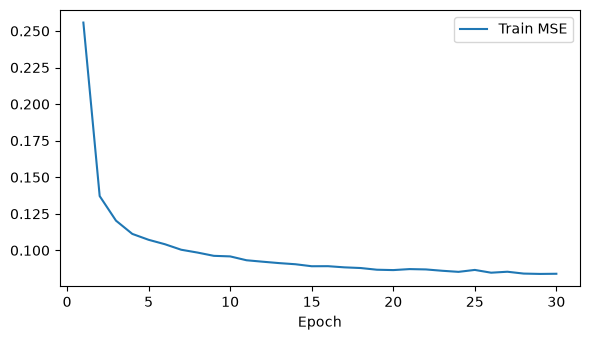

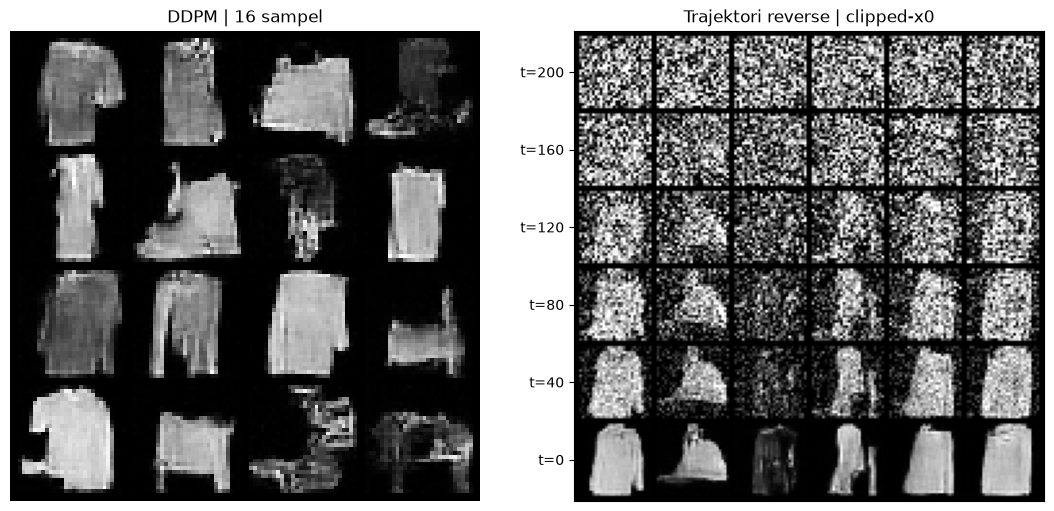

In [3]:
@torch.inference_mode()
def calc_fid_tm(real_x, fake_x):
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(DEVICE)
    for b in real_x.split(FID_BATCH): fid.update(b.to(DEVICE).repeat(1, 3, 1, 1), real=True)
    for b in fake_x.split(FID_BATCH): fid.update(b.to(DEVICE).repeat(1, 3, 1, 1), real=False)
    return float(fid.compute())

def calc_latency(fn, runs=5):
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    fn()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs): fn()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) * 1000.0 / runs

test_x = splits["test"].tensors[0]
with torch.inference_mode():
    rng = torch.Generator(device=DEVICE).manual_seed(SEED)
    sample_batches = []
    for start in range(0, FID_N, 256):
        count = min(256, FID_N - start)
        noise = torch.randn((count, 1, 28, 28), device=DEVICE, generator=rng)
        sample_batches.append(model.sample(noise, rng).cpu())
    gen_samples = torch.cat(sample_batches)
    fid_test = calc_fid_tm(test_x[:FID_N], gen_samples)
    rng_l = torch.Generator(device=DEVICE).manual_seed(SEED + 2)
    lat_ms = calc_latency(lambda: model.sample(torch.randn((64, 1, 28, 28), device=DEVICE, generator=rng_l), rng_l))
    rng_t = torch.Generator(device=DEVICE).manual_seed(SEED + 3)
    traj_steps = (model.steps, 160, 120, 80, 40, 0)
    noise = torch.randn((6, 1, 28, 28), device=DEVICE, generator=rng_t)
    _, traj = model.sample(noise, rng_t, record=set(traj_steps))

pd.DataFrame([{"Model": "DDPM", "Epoch": chosen["DDPM"], f"FID Test (N={FID_N})": fid_test, "Latensi Batch 64 (ms)": lat_ms}]).to_csv(METRIC_DIR / "ddpm_eval.csv", index=False)
print(f"DDPM Test FID (TorchMetrics, N={FID_N}): {fid_test:.4f} | Latensi Batch 64: {lat_ms:.3f} ms")

hdf = pd.read_csv(METRIC_DIR / "ddpm_history.csv")
plt.figure(figsize=(6, 3.5)); plt.plot(hdf["epoch"], hdf["train_mse"], label="Train MSE"); plt.xlabel("Epoch"); plt.legend(); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
axes[0].imshow(make_grid(gen_samples[:16], nrow=4, padding=2).permute(1, 2, 0).numpy())
axes[0].set_title("DDPM | 16 sampel")
axes[0].axis("off")

padding = 2
height = traj[0].shape[-2]
positions = [padding + row * (height + padding) + (height - 1) / 2
             for row in range(len(traj_steps))]
axes[1].imshow(make_grid(torch.cat(traj), nrow=6, padding=padding).permute(1, 2, 0).numpy())
axes[1].set_title("Trajektori reverse | clipped-x0")
axes[1].set(xticks=[], yticks=positions, yticklabels=[f"t={step}" for step in traj_steps])
figure_dir = ROOT / "results/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "ddpm_samples_and_trajectory.png", dpi=160)
plt.show()